Implement K-Mediod Algorithm on a credit card dataset. Determine the number of clusters using the Silhouette Method. Dataset link: https://www.kaggle.com/datasets/arjunbhasin2013/ccdata  

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, pairwise_distances

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, pairwise_distances
from sklearn.decomposition import PCA

In [14]:
df = pd.read_csv('CC GENERAL.csv')

df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [15]:
print("Dataset Shape:", df.shape)

df.info()

df.describe()

Dataset Shape: (8950, 18)
<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int6

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [16]:
print(df.isnull().sum())

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64


In [17]:
df = df.drop('CUST_ID', axis=1)

df.fillna(df.median(), inplace=True)

print("Missing Values:", df.isnull().sum().sum())

Missing Values: 0


In [18]:
scaler = StandardScaler()

X = scaler.fit_transform(df)

print("Scaled Data Shape:", X.shape)

Scaled Data Shape: (8950, 17)


In [19]:
def kmedoids(D, k, max_iter=50, random_state=42):

    np.random.seed(random_state)

    n = D.shape[0]
    medoids = np.random.choice(n, k, replace=False)

    for _ in range(max_iter):

        labels = np.argmin(D[:, medoids], axis=1)
        new_medoids = medoids.copy()

        for i in range(k):
            points = np.where(labels == i)[0]

            if len(points) > 0:
                costs = D[np.ix_(points, points)].sum(axis=1)
                new_medoids[i] = points[np.argmin(costs)]

        if np.array_equal(medoids, new_medoids):
            break

        medoids = new_medoids

    labels = np.argmin(D[:, medoids], axis=1)

    return medoids, labels

In [20]:
np.random.seed(42)

sample_size = min(1500, len(X))

indices = np.random.choice(len(X), sample_size, replace=False)

X_sample = X[indices]

D = pairwise_distances(X_sample)

print("Sample Shape:", X_sample.shape)

Sample Shape: (1500, 17)


In [21]:
K_range = range(2, 9)

sil_scores = []

for k in K_range:

    medoids, labels = kmedoids(D, k)

    score = silhouette_score(
        D, labels, metric='precomputed'
    )

    sil_scores.append(score)

    print("K =", k, "Silhouette Score =", score)

K = 2 Silhouette Score = 0.16881843255393053


K = 3 Silhouette Score = 0.14626742561988618
K = 4 Silhouette Score = 0.13564641726038604


K = 5 Silhouette Score = 0.07660668009969934
K = 6 Silhouette Score = 0.09116465760013472


K = 7 Silhouette Score = 0.10988409810439789
K = 8 Silhouette Score = 0.10987635786631238


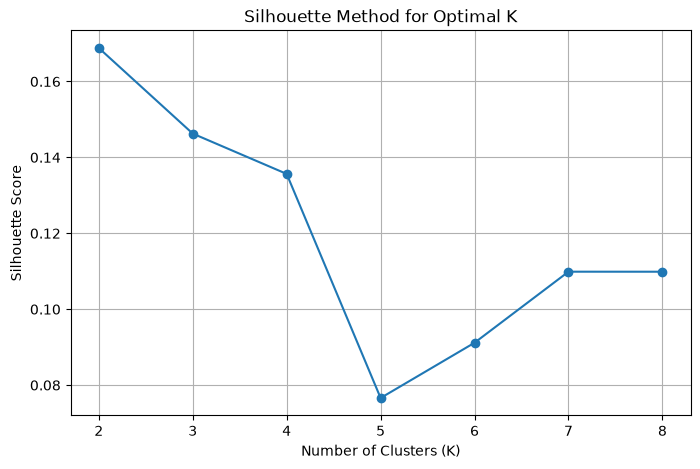

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(K_range, sil_scores, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method for Optimal K")

plt.grid(True)
plt.show()

In [23]:
best_k = list(K_range)[np.argmax(sil_scores)]

print("Optimal Number of Clusters:", best_k)
print("Best Silhouette Score:", max(sil_scores))

Optimal Number of Clusters: 2
Best Silhouette Score: 0.16881843255393053


In [24]:
best_medoids, sample_labels = kmedoids(D, best_k)

print("Optimal K:", best_k)
print("Medoid Indices:", best_medoids)

Optimal K: 2
Medoid Indices: [1309  248]


In [25]:
medoid_points = X_sample[best_medoids]

all_distances = pairwise_distances(X, medoid_points)

df['Cluster'] = np.argmin(all_distances, axis=1)

print(df.head())

       BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0    40.900749           0.818182      95.40              0.00   
1  3202.467416           0.909091       0.00              0.00   
2  2495.148862           1.000000     773.17            773.17   
3  1666.670542           0.636364    1499.00           1499.00   
4   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.083333   
1                    0.000000                          0.000000   
2                

In [26]:
print(df['Cluster'].value_counts().sort_index())

Cluster
0    3874
1    5076
Name: count, dtype: int64


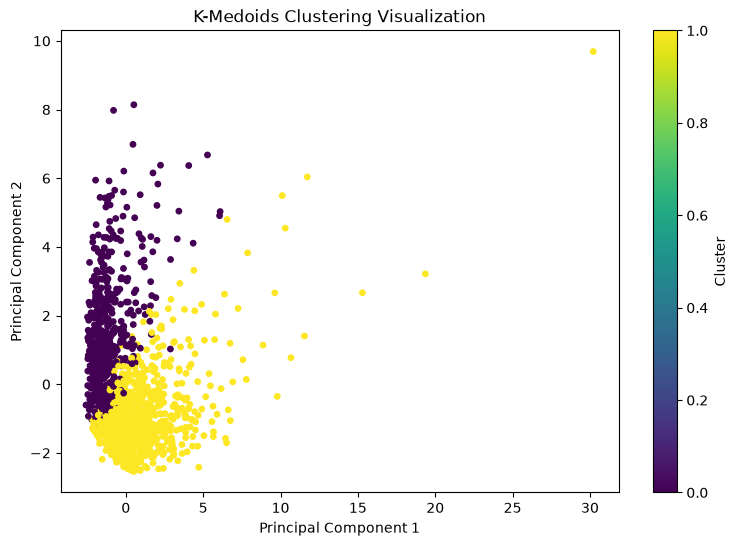

In [27]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_sample)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=sample_labels,
    cmap='viridis',
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Medoids Clustering Visualization")

plt.colorbar(label="Cluster")
plt.show()

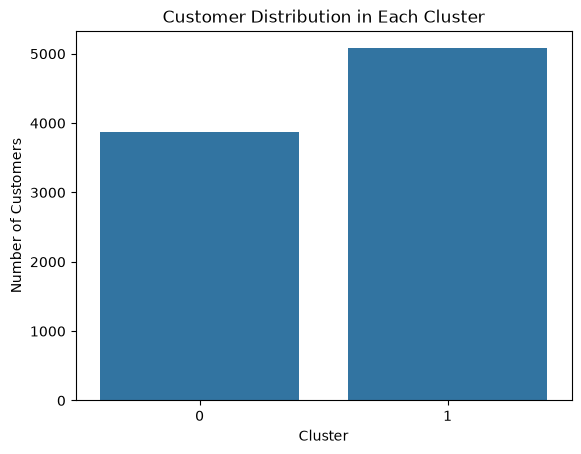

In [28]:
sns.countplot(data=df, x='Cluster')

plt.title("Customer Distribution in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

In [29]:
print("Final Number of Clusters:", best_k)

print("\nCluster Sizes:")
print(df['Cluster'].value_counts().sort_index())

print("\nFinal Dataset:")
print(df.head())

Final Number of Clusters: 2

Cluster Sizes:
Cluster
0    3874
1    5076
Name: count, dtype: int64

Final Dataset:
       BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0    40.900749           0.818182      95.40              0.00   
1  3202.467416           0.909091       0.00              0.00   
2  2495.148862           1.000000     773.17            773.17   
3  1666.670542           0.636364    1499.00           1499.00   
4   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000        

In [30]:
df.to_csv('Credit_Card_KMedoids_Results.csv', index=False)

print("Results saved successfully!")

Results saved successfully!


In [31]:
# !pip install pandas numpy matplotlib seaborn scikit-learn